In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
FILENAME = 'BankNoteAuthentication.csv'
random_state = 42
test_size = 0.3
df = pd.read_csv(FILENAME)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [4]:
df.isna().sum()

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

In [5]:
features = ['variance', 'skewness', 'curtosis', 'entropy']
target = ['class']

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=test_size,
    random_state=random_state
)

In [6]:
X_train.describe()

,variance,skewness,curtosis,entropy
count,960.000000,960.000000,960.000000,960.000000
mean,0.409875,1.850630,1.446693,-1.199246
std,2.858811,5.923107,4.351654,2.085500
min,-7.042100,-13.773100,-5.261300,-8.548200
25%,-1.805350,-1.875850,-1.457600,-2.382450
50%,0.398130,2.405550,0.596925,-0.615095
75%,2.928000,6.748925,3.146250,0.399980
max,6.824800,12.951600,17.927400,2.162500


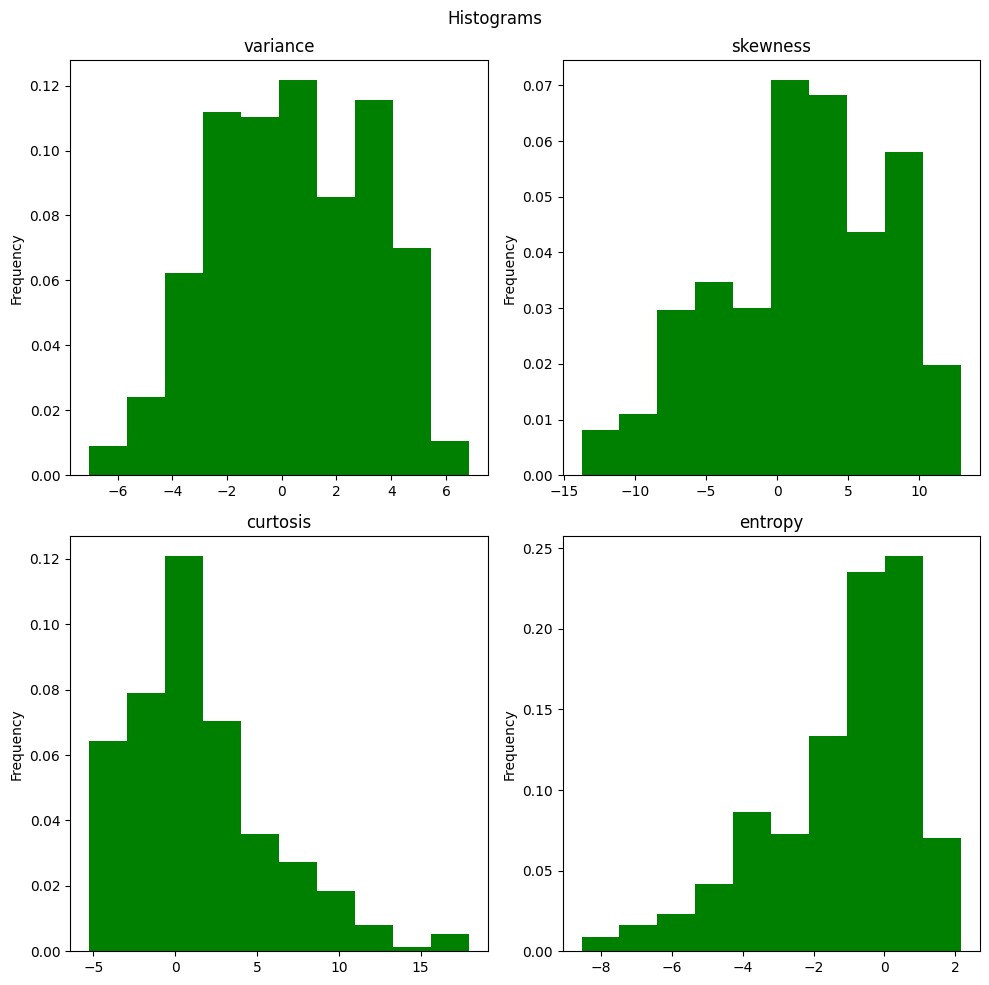

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(10,10))

for i, feature in enumerate(features):
    X_train[feature].plot(
        kind='hist',
        title=feature,
        density=True,
        color='green',
        ax=ax[i//2, i%2]
    )

plt.suptitle('Histograms')
plt.tight_layout()
plt.show()

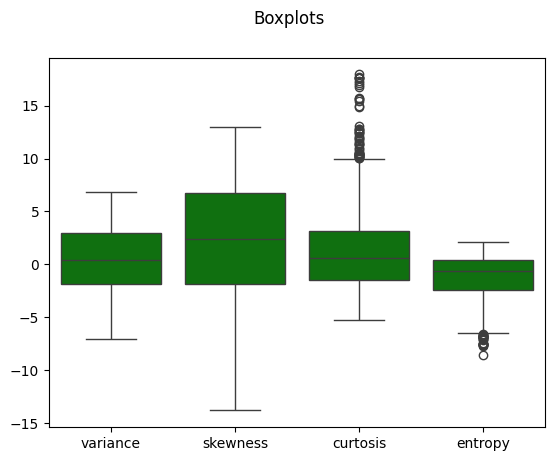

In [8]:
sns.boxplot(X_train, color='green')
plt.suptitle('Boxplots')
plt.show()

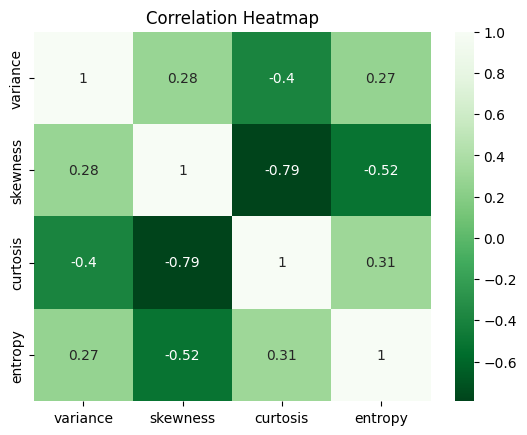

In [9]:
corr = X_train.corr()
ax = sns.heatmap(
    data=corr,
    annot=True,
    cmap='Greens_r'
)
ax.set_title('Correlation Heatmap')
plt.show()

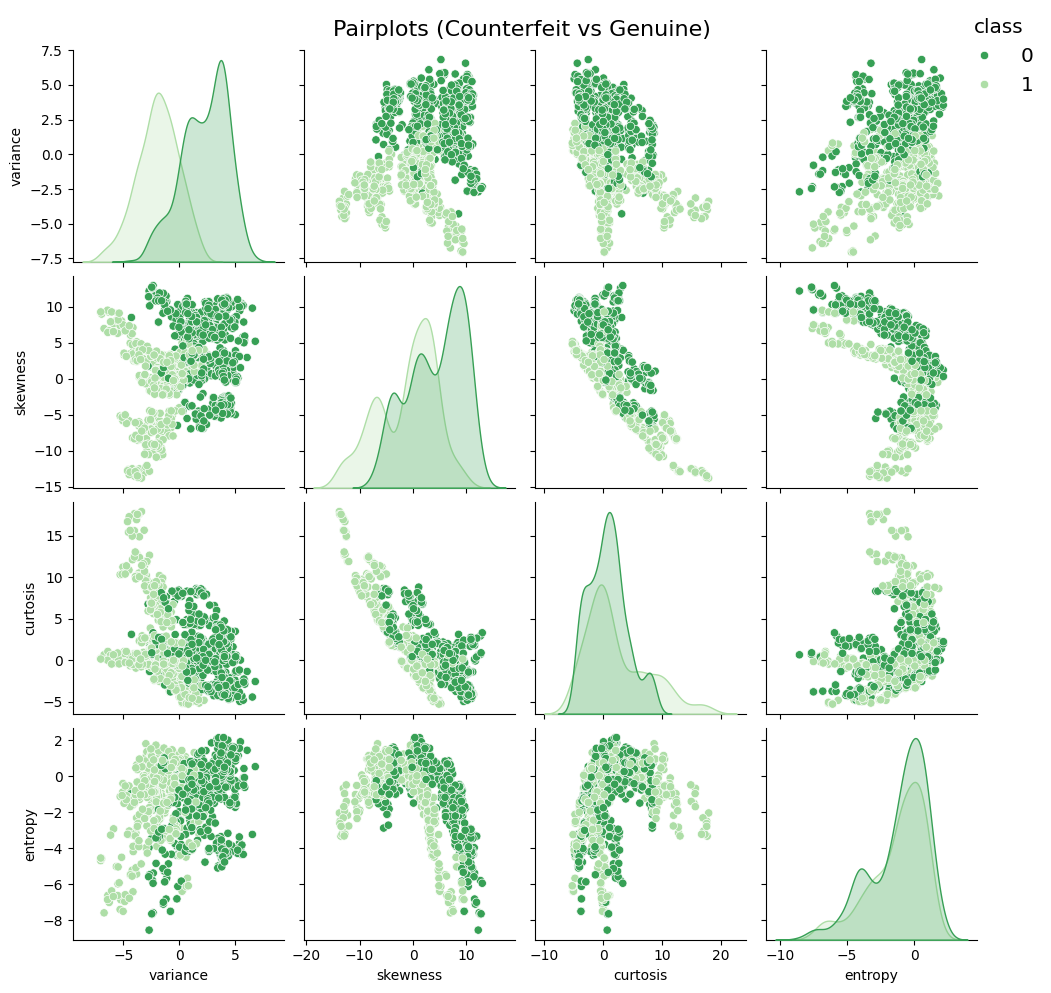

In [10]:
g = sns.pairplot(
    pd.concat((X_train, y_train), axis=1),
    hue='class',
    palette='Greens_r'
)
g.figure.subplots_adjust(top=0.95, right=0.93)
sns.move_legend(
    g,
    loc='upper right',
    fontsize='x-large',
    title_fontsize='x-large'
)
g.figure.suptitle('Pairplots (Counterfeit vs Genuine)', fontsize=16)
plt.show()

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [16]:
X_train_scaled = StandardScaler().fit_transform(X_train)
X_test_scaled = StandardScaler().fit_transform(X_test)

svc = SVC().fit(X_train_scaled, y_train)
y_pred = svc.predict(X_test_scaled)

accuracy_score(y_test, y_pred)

C:\Users\aaron\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


1.0